# Firing rate and sniff HMM state

Does a unit's firing rate depend on the **3-state sniff HMM** state? The states come from cbm-hmm's per-session fits
(`E:/cbm-odor/hmm/<mouse>/<session>/sniff_hmm_3state.csv`): each session cut into 10 s bins, each bin described by its
distribution of sniff intervals and the mouse's running speed, three states per session numbered by sniff rate
(state 0 the session's slowest sniffing, state 2 its fastest). cbm-hmm's `6_sniff_3state.ipynb` guesses that
**state 0 is at the port** (drinking, with the run to the port in the same bin), **state 1 is running** through the
arena, and **state 2 is exploring** away from the reward (rearing, sitting up, end walls), checked in the video of
two sessions. The HMM never sees spikes.

Scores come from `sniff-raster-python/sniff_hmm_model.py` (`E:/cbm-odor/sniff/sniff_hmm_model.csv`). It uses
`sniff_rate_model.py`'s bins, z-scores, covariates, folds and cross-validated R², so the two notebooks compare
directly (`8_sniff_rate_model.ipynb`):

- **Bins:** 250 ms, each with the unit's z-scored spike count and the HMM state of the nearest frame.
- **The confound:** the states are built from sniffing and running, and they lean toward the task epochs and
  toward late in the session. A state effect could be a running, epoch, drift or sniff-rate effect. So the state is
  scored on top of three baselines:
  - `cov`: epoch + body speed (spline) + time in session (spline), as in `8_` → `dr2_state`
  - `cov_spl`: `cov` + a spline in instantaneous sniff rate → `dr2_state_sniff`
  - `cov_slow`: `cov` + splines in sniff rate and log speed averaged over 10 s, the time scale the HMM sees →
    `dr2_state_slow`. This asks whether the discrete state is more than a smoothed version of its own inputs.
- **Significance:** `p_*` from circularly shifting the state sequence against everything else (200 shifts of at
  least 60 s; states come in runs of 25-40 s).

Units with fewer than 100 spikes in usable bins are left out. Sessions are the 76 with both MATLAB sniff params and
a 3-state fit.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = 'E:/cbm-odor/'
KEYS = ['mouse', 'session', 'region', 'cluster']
EPOCHS = ['search', 'retrieval', 'consumption']
EPOCH_COLORS = dict(search='#2a78d6', retrieval='#eb6834', consumption='#1baf7a')
REGION_COLORS = dict(ob='#2a78d6', hc='#eb6834')
REGION_NAMES = dict(ob='OB', hc='CA1')
STATES = [0, 1, 2]
STATE_NAMES = {0: '0 port', 1: '1 running', 2: '2 exploring'}
STATE_COLORS = ['#d4ac00', '#00a9bd', '#c800c8']  # cbm-hmm's sniff 3-state yellow, cyan, magenta, darkened for white
TESTS = dict(state='beyond behavior', state_sniff='+ sniff rate', state_slow='+ slow sniff & speed')
ALPHA = 0.05
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '0.92', 'grid.linewidth': 0.6, 'axes.axisbelow': True})

d = pd.read_csv(ROOT + 'sniff/sniff_hmm_model.csv', dtype={'mouse': str, 'session': str})
sess = pd.read_csv(ROOT + 'sniff/sniff_hmm_sessions.csv', dtype={'mouse': str, 'session': str})
read = lambda f, cols: pd.read_csv(ROOT + f, dtype={'mouse': str, 'session': str})[KEYS + cols]
d = (d.merge(read('sniff/mt_cell_inventory.csv', ['cell_type']), on=KEYS, how='left')
      .merge(read('sniff/sniff_locking.csv', ['info_p']).rename(columns={'info_p': 'sniff_lock_p'}), on=KEYS, how='left')
      .merge(read('theta/theta_locking.csv', ['mrl_p']).rename(columns={'mrl_p': 'theta_p'}), on=KEYS, how='left')
      .merge(read('sniff/sniff_rate_model.csv', ['dr2_spl', 'p_spl']), on=KEYS, how='left'))
d['sniff_locked'] = np.where(d['sniff_lock_p'].isna(), np.nan, d['sniff_lock_p'] < ALPHA)
d['theta_locked'] = np.where(d['theta_p'].isna(), np.nan, d['theta_p'] < ALPHA)
for t in TESTS:
    d[f'sig_{t}'] = d[f'p_{t}'] < ALPHA
d['sig'] = d['sig_state']
print(f"{len(sess)} sessions, {sess['mouse'].nunique()} mice")
print(d.groupby('region').size().rename(index=REGION_NAMES).to_string())

74 sessions, 8 mice
region
CA1    1859
OB     1183


## 1. The states in these bins

Per session (one grey line each): each state's share of the 250 ms bins, mean sniff rate, median body speed and
epochs. Sniff rate here is from the MATLAB sniff params, the HMM's from the Python ones, so the numbers differ a
little from cbm-hmm's. This is the confound: the states differ in running and in epoch, not only in sniffing.

,share,sniff_hz,speed,search,retrieval,consumption
0 port,0.193,5.730,162.154,0.575,0.096,0.334
1 running,0.350,6.347,249.486,0.729,0.081,0.169
2 exploring,0.411,7.538,186.184,0.913,0.034,0.053


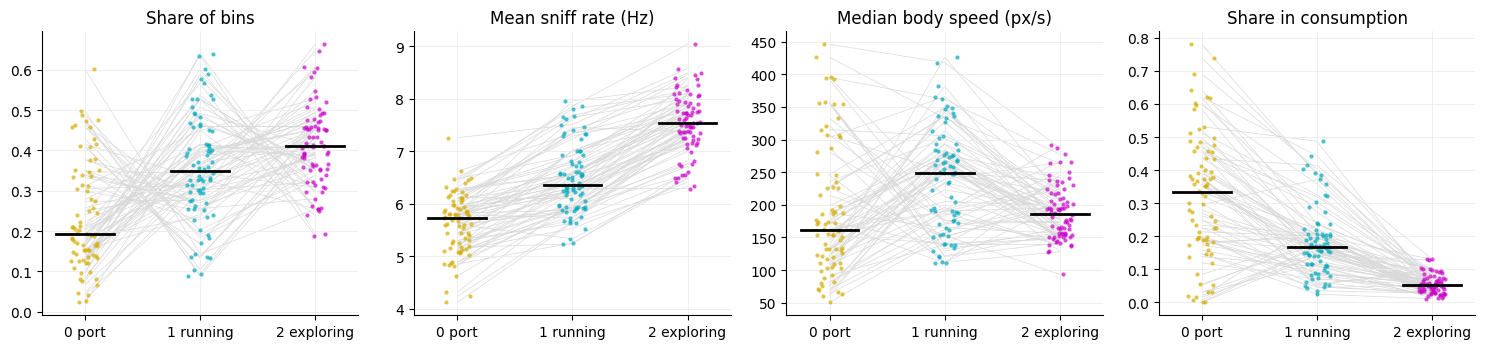

In [2]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (col, lab) in zip(axs, [('share', 'Share of bins'), ('sniff_hz', 'Mean sniff rate (Hz)'),
                                ('speed', 'Median body speed (px/s)'), ('consumption', 'Share in consumption')]):
    v = sess[[f'{col}_{k}' for k in STATES]].to_numpy()
    ax.plot(STATES, v.T, color='0.85', lw=0.5, zorder=0)
    for k in STATES:
        ax.scatter(np.full(len(v), k) + np.random.default_rng(k).uniform(-0.12, 0.12, len(v)), v[:, k], s=9,
                   color=STATE_COLORS[k], alpha=0.7, linewidths=0)
        ax.plot([k - 0.25, k + 0.25], [np.nanmedian(v[:, k])] * 2, color='k', lw=2)
    ax.set(xticks=STATES, xticklabels=[STATE_NAMES[k] for k in STATES], title=lab)
fig.tight_layout()
t = pd.DataFrame({STATE_NAMES[k]: {c: sess[f'{c}_{k}'].median() for c in ['share', 'sniff_hz', 'speed'] + EPOCHS}
                  for k in STATES}).T
t.round(3)

**The states sort as cbm-hmm described, and they differ in more than sniffing.** Across sessions the states sniff at
5.7, 6.3 and 7.5 Hz (medians). State 1 runs fastest (249 px/s, against 162 and 186). State 0 is a third consumption,
and state 2 is 91% search. So comparing firing between states also compares running and epoch, which is why the
state is scored on top of the covariates.

## 2. Does the state explain firing beyond behavior?

Left: the share of units whose firing the state explains significantly, beyond each baseline (5% expected by chance,
dashed). Right: how much it adds beyond `cov` (`dr2_state`, the gain in cross-validated R²), next to what
instantaneous sniff rate adds in `8_` (`dr2_spl`) for the same units. R² values are small for every model at 250 ms;
the table prints `cv_r2_cov` and `cv_r2_state` (the state alone) for scale.

,n,sig_state,sig_state_sniff,sig_state_slow,cv_r2_cov,cv_r2_state,dr2_state,dr2_state_slow,dr2_spl
region,,,,,,,,,
CA1,1859,0.3039,0.2700,0.1506,0.0729,0.0057,-0.0,-0.0003,0.0023
OB,1183,0.3347,0.2282,0.1327,0.0452,0.0040,0.0,-0.0004,0.0119


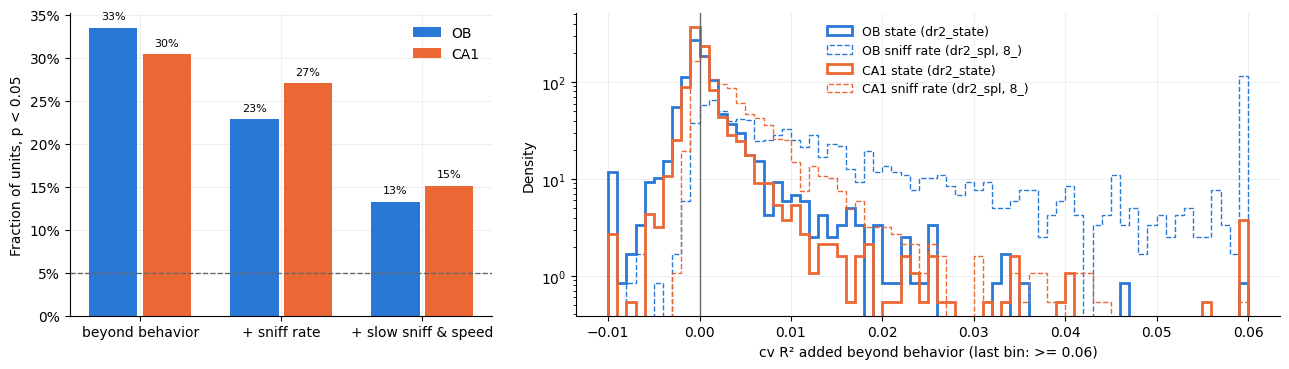

In [3]:
summ = d.groupby('region').agg(n=('cluster', 'size'), **{f'sig_{t}': (f'sig_{t}', 'mean') for t in TESTS},
                               cv_r2_cov=('cv_r2_cov', 'median'), cv_r2_state=('cv_r2_state', 'median'),
                               dr2_state=('dr2_state', 'median'), dr2_state_slow=('dr2_state_slow', 'median'),
                               dr2_spl=('dr2_spl', 'median')).rename(index=REGION_NAMES)
display(summ.round(4))
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw=dict(width_ratios=[1.2, 2]))
ax = axs[0]
w = 0.38
for i, r in enumerate(['ob', 'hc']):
    vals = [d.loc[d.region == r, f'sig_{t}'].mean() for t in TESTS]
    x = np.arange(len(TESTS)) + (i - 0.5) * w
    ax.bar(x, vals, w * 0.9, color=REGION_COLORS[r], label=REGION_NAMES[r])
    for xi, v in zip(x, vals):
        ax.text(xi, v + 0.01, f'{v:.0%}', ha='center', fontsize=8)
ax.axhline(ALPHA, color='0.4', lw=1, ls='--')
ax.set(xticks=range(len(TESTS)), xticklabels=TESTS.values(), ylabel='Fraction of units, p < 0.05')
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
ax.legend(frameon=False)
bins = np.linspace(-0.01, 0.06, 71)  # the last bin collects everything above
ax = axs[1]
for r in ['ob', 'hc']:
    g = d[d.region == r]
    ax.hist(g['dr2_state'].clip(bins[0], bins[-1]), bins, histtype='step', lw=2, color=REGION_COLORS[r],
            label=f'{REGION_NAMES[r]} state (dr2_state)', density=True)
    ax.hist(g['dr2_spl'].clip(bins[0], bins[-1]), bins, histtype='step', lw=1, ls='--', color=REGION_COLORS[r],
            label=f'{REGION_NAMES[r]} sniff rate (dr2_spl, 8_)', density=True)
ax.axvline(0, color='0.4', lw=1)
ax.set(xlabel='cv R² added beyond behavior (last bin: >= 0.06)', ylabel='Density', yscale='log')
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()

**The state explains firing in about a third of units beyond behavior, but it adds very little.**

- 33% of OB and 30% of CA1 units are significant beyond `cov`, against 5% by chance. The share falls to 23% / 27%
  once instantaneous sniff rate is in the baseline, and to 13% / 15% once 10 s sniff rate and speed are.
- The gain is small. Among significant units the median `dr2_state` is 0.003 (OB) and 0.0025 (CA1), against
  `cv_r2_cov` of 0.045 and 0.073. Over all units it is about 0: two dummies that predict nothing cost a little
  held-out R², so half the units come out negative. For significant units, the median rate in the unit's highest
  state is 1.36-1.38 times that in its lowest (raw, all bins).
- **In OB, instantaneous sniff rate matters far more than the state** (dashed lines: `dr2_spl` from `8_`, median
  0.012, and significant in 92% of OB units). In CA1 the two are closer.

## 3. State or sniff rate?

The state is built from sniffing, so the question is which carries the information. For each unit,
`dr2_state_sniff` is what the state adds on top of behavior and instantaneous sniff rate, and `dr2_sniff_state` is
what instantaneous sniff rate adds on top of behavior and the state. Units above the diagonal are better described
by the state than by the sniff rate. Below, the same for the 10 s smoothed signals: does the discrete state carry
anything a smooth sniff rate and speed do not?

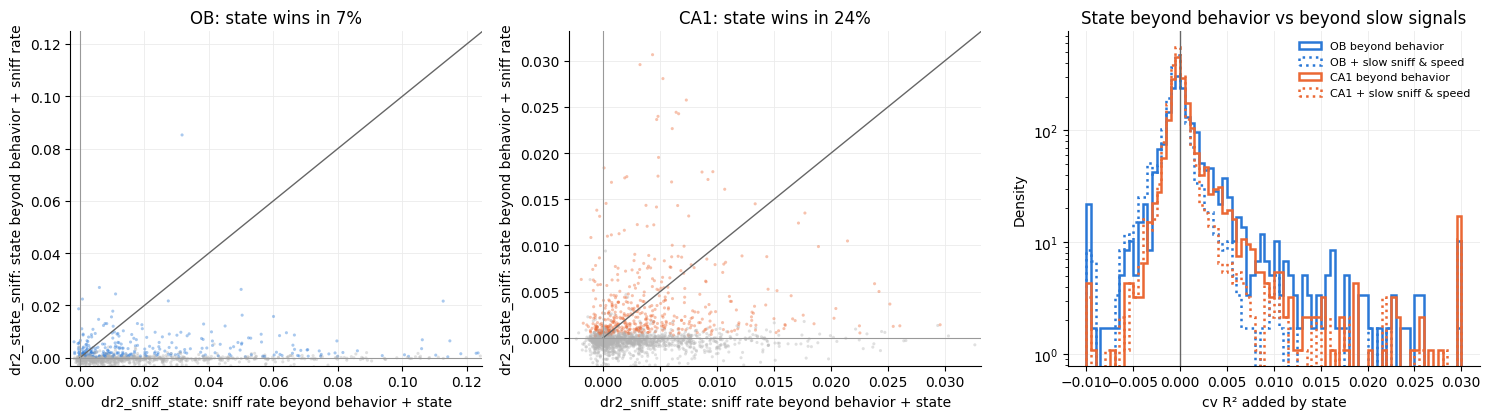

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, r in zip(axs[:2], ['ob', 'hc']):
    g = d[d.region == r]
    ax.scatter(g['dr2_sniff_state'], g['dr2_state_sniff'], s=5, alpha=0.4, linewidths=0, rasterized=True,
               color=np.where(g['sig_state_sniff'], REGION_COLORS[r], '0.7'))
    lim = np.nanpercentile(g[['dr2_sniff_state', 'dr2_state_sniff']], 99.5)
    ax.plot([0, lim], [0, lim], color='0.4', lw=1)
    ax.axhline(0, color='0.6', lw=0.8); ax.axvline(0, color='0.6', lw=0.8)
    ax.set(xlim=(-0.003, lim), ylim=(-0.003, lim), xlabel='dr2_sniff_state: sniff rate beyond behavior + state',
           ylabel='dr2_state_sniff: state beyond behavior + sniff rate',
           title=f"{REGION_NAMES[r]}: state wins in {(g['dr2_state_sniff'] > g['dr2_sniff_state']).mean():.0%}")
ax = axs[2]
bins = np.linspace(-0.01, 0.03, 81)
for r in ['ob', 'hc']:
    for t, ls in [('state', '-'), ('state_slow', ':')]:
        ax.hist(d.loc[d.region == r, f'dr2_{t}'].clip(bins[0], bins[-1]), bins, histtype='step', lw=1.8, ls=ls,
                color=REGION_COLORS[r], density=True, label=f'{REGION_NAMES[r]} {TESTS[t]}')
ax.axvline(0, color='0.4', lw=1)
ax.set(xlabel='cv R² added by state', ylabel='Density', yscale='log', title='State beyond behavior vs beyond slow signals')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()

**The state rarely beats sniff rate.** In OB the state adds more than instantaneous sniff rate in only 7% of
units. Sniff rate beyond the state is a median 0.011, and the state beyond sniff rate is about 0. In CA1 the state
wins in 24% of units (sniff rate beyond state, median 0.002). Beyond the 10 s sniff rate and speed, the state's
gains are mostly at or below 0. What the state carries beyond its own inputs is small, and it is significant in
13-15% of units.

## 4. Which state, and which direction?

For units significant beyond behavior (`p_state < 0.05`): the mean z in each state, raw and as the residual after
`cov`, and the raw mean within search bins only (the epoch held fixed; search is the one epoch all three states
share). Lines are units, thick lines the median. The bars count each unit's preferred state (largest partial z).

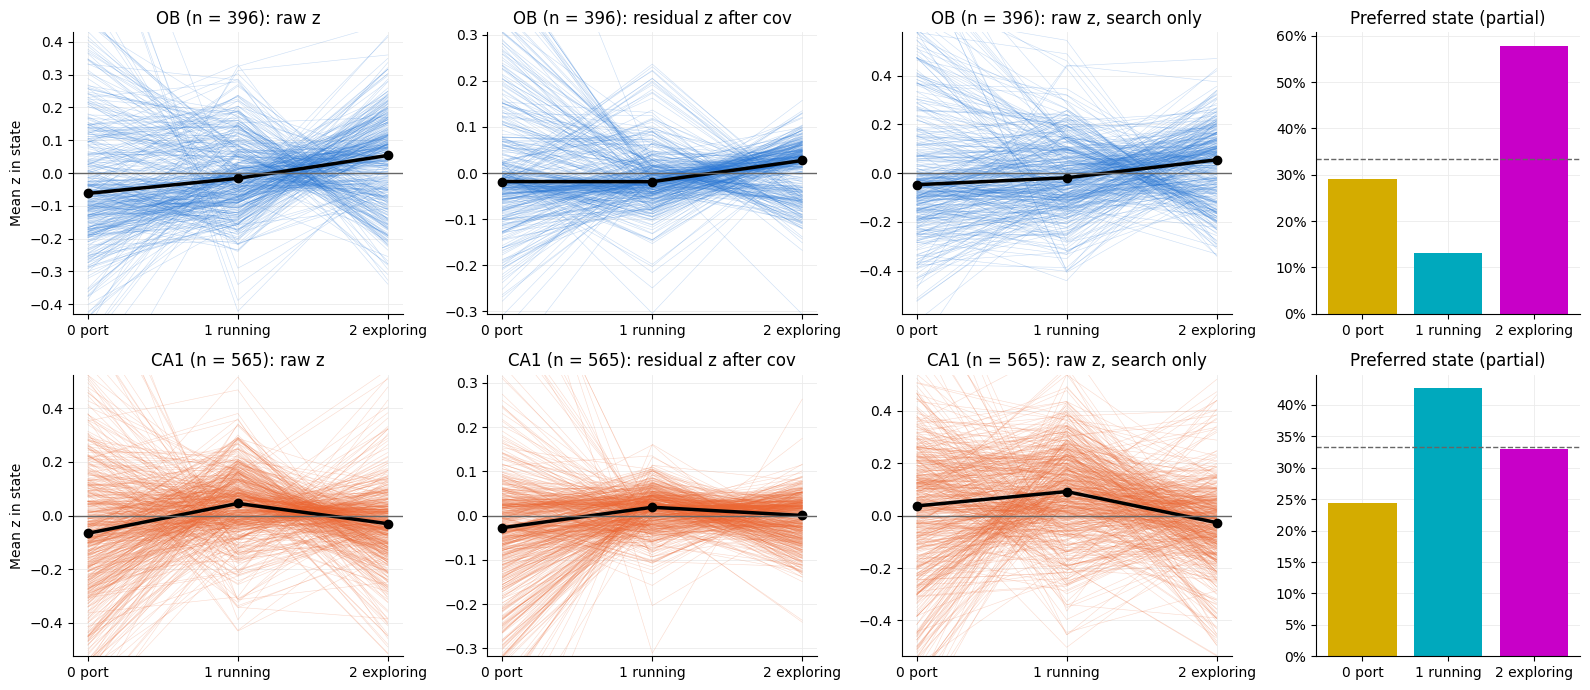

In [5]:
fig, axs = plt.subplots(2, 4, figsize=(16, 7), gridspec_kw=dict(width_ratios=[1, 1, 1, 0.8]))
for row, r in zip(axs, ['ob', 'hc']):
    g = d[(d.region == r) & d.sig]
    for ax, (pre, lab) in zip(row[:3], [('z', 'raw z'), ('partial_z', 'residual z after cov'), ('search_z', 'raw z, search only')]):
        v = g[[f'{pre}_{k}' for k in STATES]].to_numpy()
        ax.plot(STATES, v.T, color=REGION_COLORS[r], lw=0.4, alpha=0.25)
        ax.plot(STATES, np.nanmedian(v, 0), color='k', lw=2.5, marker='o')
        ax.axhline(0, color='0.4', lw=1)
        lim = np.nanpercentile(np.abs(v), 98)
        ax.set(xticks=STATES, xticklabels=[STATE_NAMES[k] for k in STATES], ylim=(-lim, lim),
               title=f'{REGION_NAMES[r]} (n = {len(g)}): {lab}')
    ax = row[3]
    c = g['pref_state'].value_counts().reindex(STATES, fill_value=0)
    ax.bar(STATES, c / c.sum(), color=STATE_COLORS)
    ax.axhline(1 / 3, color='0.4', lw=1, ls='--')
    ax.set(xticks=STATES, xticklabels=[STATE_NAMES[k] for k in STATES], title='Preferred state (partial)')
    ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
for ax in axs[:, 0]:
    ax.set_ylabel('Mean z in state')
fig.tight_layout()

**OB units fire most in state 2 (exploring), CA1 units in state 1 (running).** Among significant units, 58% of OB
units peak in state 2 after the covariates (a third by chance), and only 13% in state 1. In CA1, 43% peak in state
1 and 24% in state 0. The median profiles show this too: in OB, z rises from state 0 to state 2; in CA1 it peaks
in state 1, and it does so within search as well.

**Are the raw and partial patterns the same units' patterns?** Per significant unit, the correlation across the three
states between raw and partial z, and between raw z over all bins and raw z within search. Near 1: the covariates
or the epoch do not change which state the unit fires most in.

In [6]:
def rowcorr(a, b):
    a, b = a - a.mean(1, keepdims=True), b - b.mean(1, keepdims=True)
    return (a * b).sum(1) / np.sqrt((a ** 2).sum(1) * (b ** 2).sum(1))

rows = {}
for r in ['ob', 'hc']:
    g = d[(d.region == r) & d.sig]
    z, pz, sz = (g[[f'{p}_{k}' for k in STATES]].to_numpy() for p in ('z', 'partial_z', 'search_z'))
    ok = np.isfinite(sz).all(1)
    rows[REGION_NAMES[r]] = {'raw vs partial, median r': np.median(rowcorr(z, pz)),
                             'raw vs search-only, median r': np.median(rowcorr(z[ok], sz[ok])),
                             'units with all 3 states in search': ok.sum()}
pd.DataFrame(rows).round(2)

,OB,CA1
"raw vs partial, median r",0.93,0.91
"raw vs search-only, median r",0.99,0.98
units with all 3 states in search,396.00,565.00


**The covariates shrink the state differences but do not change their pattern.** Removing epoch, speed and time
roughly halves the spread of a significant unit's state means: the median range across the three states goes from
0.29-0.31 z to 0.13-0.15 z. But the pattern is the same unit by unit (raw vs partial, median r 0.91-0.93), and it is
nearly identical within search alone (0.98-0.99). So the state effect is not epoch in disguise.

## 5. By unit type

Fraction significant (beyond behavior) and median `dr2_state`, by type, as in `8_`. Mice contribute different mixes
of types, so each comparison is repeated within mouse: the type difference in each mouse with at least 10 units of
both types, and a Wilcoxon test across those mice. With 5 mice the smallest possible two-sided p is 0.0625, so the
'mice same sign' column says more than p.

In [7]:
groupings = [('ob', 'cell_type', 'tufted', 'mitral', 'OB tufted vs mitral'),
             ('ob', 'sniff_locked', 1.0, 0.0, 'OB sniff-locked vs not'),
             ('hc', 'sniff_locked', 1.0, 0.0, 'CA1 sniff-locked vs not'),
             ('hc', 'theta_locked', 1.0, 0.0, 'CA1 theta-locked vs not'),
             ('hc', 'group', 'good', 'mua', 'CA1 good vs mua')]
rows = []
for r, col, a, b, lab in groupings:
    g = d[(d.region == r) & d[col].notna()]
    for metric in ['sig', 'dr2_state']:
        agg = 'mean' if metric == 'sig' else 'median'
        pooled = [g.loc[g[col] == v, metric].agg(agg) for v in (a, b)]
        per = g.groupby(['mouse', col])[metric].agg(agg).unstack(col)
        cnt = g.groupby(['mouse', col]).size().unstack(col)
        ok = (cnt.reindex(columns=[a, b]) >= 10).all(axis=1)
        diff = (per[a] - per[b])[ok]
        p = stats.wilcoxon(diff)[1] if len(diff) >= 5 and diff.abs().sum() > 0 else np.nan
        rows.append({'comparison': lab, 'metric': metric, 'A': pooled[0], 'B': pooled[1], 'pooled A-B': pooled[0] - pooled[1],
                     'mice': int(ok.sum()), 'mice same sign': int((np.sign(diff) == np.sign(pooled[0] - pooled[1])).sum()),
                     'within-mouse median A-B': diff.median(), 'Wilcoxon p': p})
pd.DataFrame(rows).set_index(['comparison', 'metric']).round(4)

A       B  pooled A-B  mice  \
comparison              metric                                        
OB tufted vs mitral     sig        0.3085  0.3725     -0.0640     5   
                        dr2_state -0.0000  0.0001     -0.0001     5   
OB sniff-locked vs not  sig        0.3438  0.2968      0.0470     4   
                        dr2_state  0.0001 -0.0002      0.0003     4   
CA1 sniff-locked vs not sig        0.3597  0.2731      0.0866     8   
                        dr2_state  0.0001 -0.0001      0.0002     8   
CA1 theta-locked vs not sig        0.3281  0.1602      0.1680     6   
                        dr2_state  0.0000 -0.0002      0.0003     6   
CA1 good vs mua         sig        0.2759  0.3115     -0.0355     8   
                        dr2_state -0.0000 -0.0000      0.0000     8   

                                   mice same sign  within-mouse median A-B  \
comparison              metric                                               
OB tufted vs mitral     sig                     3                  -0.0077   
                        dr2_state               2                   0.0001   
OB sniff-locked vs not  sig                     3                   0.1668   
                        dr2_state               3                   0.0004   
CA1 sniff-locked vs not sig                     8                   0.0601   
                        dr2_state               6                   0.0002   
CA1 theta-locked vs not sig                     6                   0.1046   
                        dr2_state               4                   0.0003   
CA1 good vs mua         sig                     5                  -0.0281   
                        dr2_state               5                   0.0000   

                                   Wilcoxon p  
comparison              metric                 
OB tufted vs mitral     sig            1.0000  
                        dr2_state      1.0000  
OB sniff-locked vs not  sig               NaN  
                        dr2_state         NaN  
CA1 sniff-locked vs not sig            0.0078  
                        dr2_state      0.0781  
CA1 theta-locked vs not sig            0.0312  
                        dr2_state      0.1562  
CA1 good vs mua         sig            0.4609  
                        dr2_state      0.7422

**In CA1, sniff-locked and theta-locked units are more often state-modulated, and the difference holds within
mouse.** Sniff-locked: +6 points within mouse, same sign in 8 of 8 mice, p = 0.008. Theta-locked: +10 points, 6 of
6 mice, p = 0.03. The `dr2_state` differences go the same way but are tiny. **OB tufted vs mitral** shows no
difference (3 of 5 mice in the pooled direction, p = 1). CA1 good vs mua shows no consistent difference either.

## 6. Every mouse

Fraction of units significant beyond behavior, and beyond behavior + slow sniff rate and speed, in each mouse.

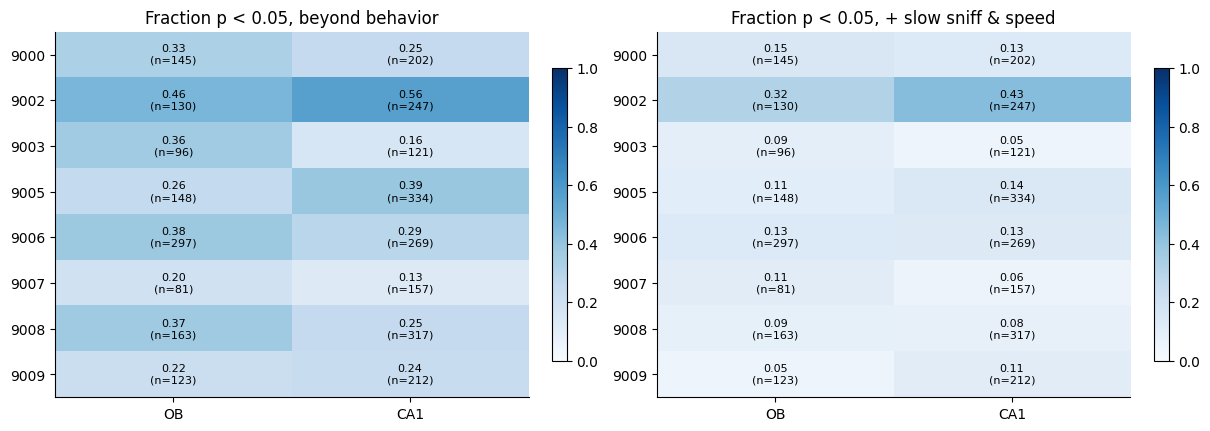

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), layout='constrained')
for ax, t in zip(axs, ['state', 'state_slow']):
    tab = d.groupby(['mouse', 'region'])[f'sig_{t}'].mean().unstack('region')[['ob', 'hc']]
    n = d.groupby(['mouse', 'region']).size().unstack('region')[['ob', 'hc']]
    im = ax.imshow(tab.values, cmap='Blues', vmin=0, vmax=1, aspect='auto')
    for (i, j), v in np.ndenumerate(tab.values):
        if np.isfinite(v):
            ax.text(j, i, f'{v:.2f}\n(n={int(n.values[i, j])})', ha='center', va='center', fontsize=8,
                    color='w' if v > 0.65 else 'k')
    ax.set(xticks=[0, 1], xticklabels=['OB', 'CA1'], yticks=range(len(tab)), yticklabels=tab.index,
           title=f'Fraction p < 0.05, {TESTS[t]}')
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.8)

**Every mouse is above chance.** The share of significant units beyond behavior ranges from 13% to 56% in CA1 and
from 20% to 46% in OB. 9002 is highest in both regions.

## 7. Example units

The three units per region with the largest `dr2_state`: firing rate (Hz) in each state over all bins, and the
partial z (after `cov`). Where the partial pattern is flatter than the raw one, part of the state difference came from
running, epoch or drift.

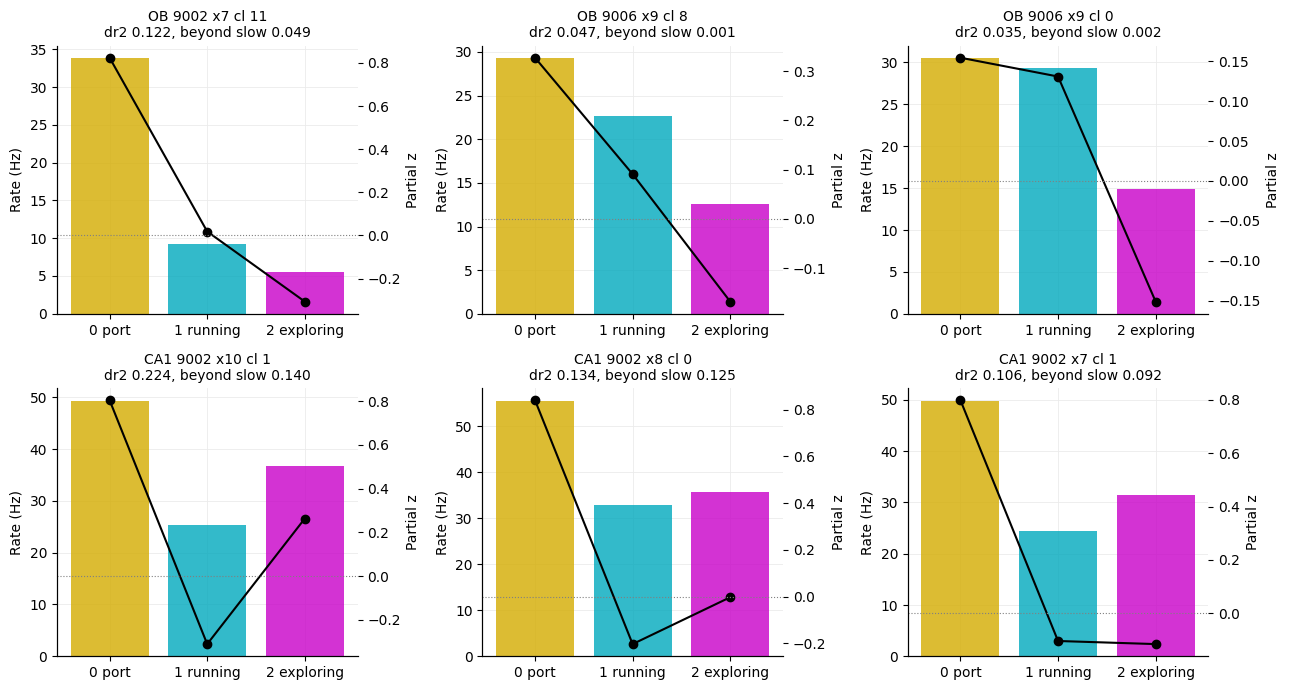

In [9]:
fig, axs = plt.subplots(2, 3, figsize=(13, 7))
for row, r in zip(axs, ['ob', 'hc']):
    idx = d[d.region == r].sort_values('dr2_state', ascending=False).index[:3]
    for ax, i in zip(row, idx):
        u = d.loc[i]
        ax.bar(STATES, [u[f'rate_hz_{k}'] for k in STATES], color=STATE_COLORS, alpha=0.8)
        ax.set(xticks=STATES, xticklabels=[STATE_NAMES[k] for k in STATES], ylabel='Rate (Hz)')
        ax.set_title(f"{REGION_NAMES[r]} {u.mouse} {u.session} cl {u.cluster}\n"
                     f"dr2 {u.dr2_state:.3f}, beyond slow {u.dr2_state_slow:.3f}", fontsize=10)
        ax2 = ax.twinx()
        ax2.plot(STATES, [u[f'partial_z_{k}'] for k in STATES], color='k', marker='o', lw=1.5)
        ax2.axhline(0, color='0.5', lw=0.8, ls=':')
        ax2.set_ylabel('Partial z')
        ax2.grid(False)
fig.tight_layout()

## Summary

- **Yes, but weakly.** The 3-state sniff HMM state explains firing beyond running speed, epoch and drift in about a
  third of OB and CA1 units (5% expected by chance). The gain in held-out R² is about 0.003, and the rate in a
  significant unit's highest state is about 1.4 times that in its lowest.
- **Most of it is sniffing and running.** In OB, instantaneous sniff rate (`8_`) explains far more than the state,
  and the state adds almost nothing on top of it. Beyond a 10 s smoothed sniff rate and speed, 13-15% of units stay
  significant with very small gains. The discrete state adds little beyond its own inputs.
- **Direction:** OB units fire most in state 2 (fastest sniffing, exploring), CA1 units in state 1 (running). The
  pattern holds after covariates and within search.
- **Types:** in CA1, sniff- and theta-locked units are more often modulated (within mouse, all mice). In OB, no
  mitral/tufted difference.
- **Caveats:** states are per session, numbered by sniff rate, and their names are cbm-hmm's guesses (checked in the
  video of two sessions). 74 sessions: 9003/x2 and 9007/x10 have no units that pass the spike threshold (as in `8_`).